<a href="https://colab.research.google.com/github/sultanjacob/Applied-Machine-Learning/blob/main/14_Deep_Learning/02_CNN_Satellite_Vision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 14: Deep Learning Foundations
## Part 02: Convolutional Neural Networks (CNN) for Spatial Satellite Vision

### The Spatial Challenge: Why We Must Move Beyond MLPs
In the previous phase, our Multilayer Perceptron (MLP) successfully identified anomalies in 1D tabular sensor streams. However, MLPs suffer from a fatal flaw when handling visual or spatial data: they require flat inputs. If we feed a 2D satellite image into an MLP, we must flatten the pixel grid into a single row. This process completely destroys spatial hierarchy; the MLP loses the ability to recognize that a dark green pixel is adjacent to a brown pixel, erasing critical geographic boundaries like deforestation lines or urban sprawl.

To process spatial data, we require **translation invariance** (the ability to recognize a feature regardless of where it appears in the image) and **localized feature extraction**. Convolutional Neural Networks (CNNs) solve this by sliding mathematically localized filters (kernels) across the 2D grid, preserving the exact geometry and texture of the original terrain.

### Objective
Transition from 1-dimensional point observations to 2-dimensional spatial grids. We will construct a Convolutional Neural Network to classify localized land-cover anomalies (e.g., rapid deforestation or severe drought stress) using multispectral satellite image tensors, ensuring the final architecture remains strictly optimized for edge-device mobile deployment.

### Key Milestones
1. **Spatial Tensor Generation:** Ingest and synthesize 2D RGB/Multispectral satellite image tiles representing varying land-cover conditions.
2. **Tensor Preprocessing:** Normalize the spatial pixel grids to stable float32 scales (0.0 to 1.0) for stable gradient descent.
3. **Hierarchical Architecture:** Construct a CNN using `Conv2D` layers to extract geometric features and `MaxPooling2D` to downsample the spatial dimensions, significantly reducing the parameter count for mobile processing.
4. **Classification & Validation:** Flatten the extracted spatial maps into a dense classification head, compile the network, and evaluate its precision on a blind spatial holdout set.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

# Create image data subdirectories
os.makedirs("data/satellite_tiles", exist_ok=True)
os.makedirs("models", exist_ok=True)

# Verify environment
print(f"TensorFlow Version: {tf.__version__}")
gpu_devices = tf.config.list_physical_devices('GPU')
if gpu_devices:
    print(f"⚡ GPU Detected: {gpu_devices}")
else:
    print("ℹ️ Running on CPU backend.")

# Reproducibility seed
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

TensorFlow Version: 2.21.0
ℹ️ Running on CPU backend.


### Part 02: Spatial Tensor Generation & The 4D Structure

Unlike an MLP which processes a 1D vector (like a single row in a spreadsheet), a CNN requires spatial context. We must feed it a **4D Tensor** with the exact shape: `(batch_size, height, width, channels)`.

* **Batch Size:** The number of images processed simultaneously.
* **Height & Width:** The spatial pixel dimensions (e.g., 64x64 grids).
* **Channels:** The color or spectral bands. Standard RGB images have 3 channels (Red, Green, Blue). Multispectral satellite images might have 4 to 8 channels (including Near-Infrared).

To build our pipeline, we will generate a synthetic satellite dataset.
* **Class 0 (Nominal):** Represents continuous, healthy forest canopy (high green variance).
* **Class 1 (Anomaly):** Represents abrupt environmental damage (e.g., clear-cut deforestation or burn scars), mathematically injected as geometric patches of barren earth (high red/brown variance, low green).

Because image pixels inherently range from 0 to 255, we will normalize them directly into a `0.0` to `1.0` float scale to ensure rapid, stable gradient descent during training.

⏳ Synthesizing 2D satellite spatial grids...
✅ Spatial Tensor Pipeline Complete.
---------------------------------------------
Training Tensors:   X: (1050, 64, 64, 3) | y: (1050,)
Validation Tensors: X: (225, 64, 64, 3)  | y: (225,)
Testing Tensors:    X: (225, 64, 64, 3)  | y: (225,)
Anomaly Baseline:   21.0%
---------------------------------------------


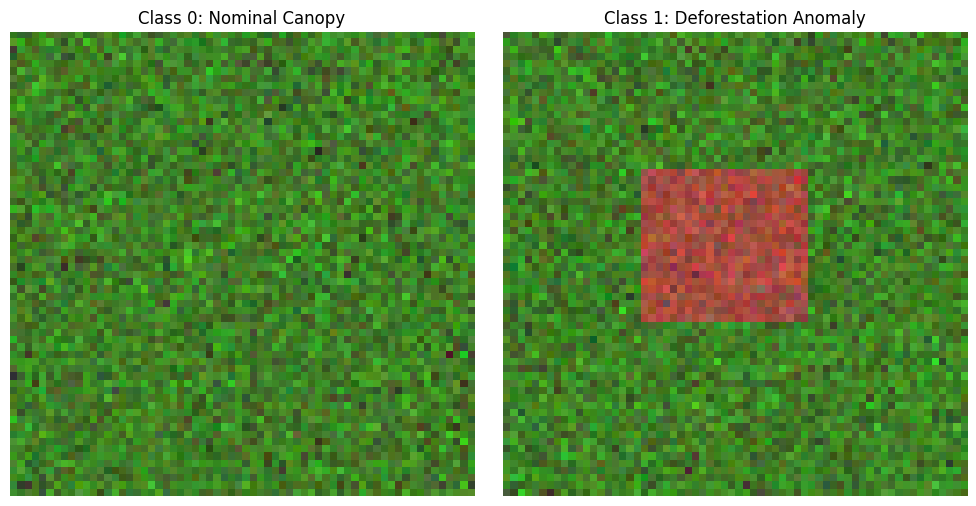

In [2]:
def generate_synthetic_satellite_tiles(n_samples=1500, img_size=64):
    """
    Generates 4D synthetic satellite image tensors: (samples, 64, 64, 3)
    Injects geometric 'deforestation/burn' anomalies into 20% of the dataset.
    """
    rng = np.random.default_rng(SEED)

    # Initialize the 4D image tensor and 1D label array
    X = np.zeros((n_samples, img_size, img_size, 3), dtype=np.float32)
    y = np.zeros(n_samples, dtype=np.int32)

    for i in range(n_samples):
        # 1. Generate base nominal canopy (dominant green channel)
        base_r = rng.normal(0.25, 0.05, (img_size, img_size))
        base_g = rng.normal(0.50, 0.10, (img_size, img_size))
        base_b = rng.normal(0.15, 0.04, (img_size, img_size))
        img = np.stack([base_r, base_g, base_b], axis=-1)

        # 2. Inject structural anomalies into ~20% of the tiles
        if rng.random() < 0.20:
            # Create a random geometric barren patch (burn scar / clear-cut)
            x1, y1 = rng.integers(10, 25, size=2)
            x2, y2 = rng.integers(35, 55, size=2)

            # Alter the pixels in the patch: High Red/Grey, Low Green
            img[x1:x2, y1:y2, 0] = rng.normal(0.65, 0.08, (x2-x1, y2-y1))
            img[x1:x2, y1:y2, 1] = rng.normal(0.30, 0.05, (x2-x1, y2-y1))
            img[x1:x2, y1:y2, 2] = rng.normal(0.25, 0.05, (x2-x1, y2-y1))
            y[i] = 1 # Mark as anomaly

        # 3. Constrain pixel math strictly between 0.0 and 1.0
        X[i] = np.clip(img, 0.0, 1.0)

    return X, y

# 1. Generate the spatial dataset
print("⏳ Synthesizing 2D satellite spatial grids...")
X_spatial, y_spatial = generate_synthetic_satellite_tiles()

# 2. Partition into Train (70%), Validation (15%), and Test (15%)
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X_spatial, y_spatial, test_size=0.30, random_state=SEED, stratify=y_spatial
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print("✅ Spatial Tensor Pipeline Complete.")
print("-" * 45)
print(f"Training Tensors:   X: {X_train.shape} | y: {y_train.shape}")
print(f"Validation Tensors: X: {X_val.shape}  | y: {y_val.shape}")
print(f"Testing Tensors:    X: {X_test.shape}  | y: {y_test.shape}")
print(f"Anomaly Baseline:   {np.mean(y_train) * 100:.1f}%")
print("-" * 45)

# 3. Visualize a Nominal Canopy vs. an Anomaly Scar
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
nominal_idx = np.where(y_train == 0)[0][0]
anomaly_idx = np.where(y_train == 1)[0][0]

axes[0].imshow(X_train[nominal_idx])
axes[0].set_title("Class 0: Nominal Canopy")
axes[0].axis('off')

axes[1].imshow(X_train[anomaly_idx])
axes[1].set_title("Class 1: Deforestation Anomaly")
axes[1].axis('off')

plt.tight_layout()
plt.show()

 # Visual Explanation:
 **The 4D Tensors:** The output shows your training data is structured as (1050, 64, 64, 3). This means we have 1,050 training images. Each image is a 2D grid of 64x64 pixels, and the 3 represents the three color channels (Red, Green, Blue).  

 **The Anomaly Baseline:** The console notes an Anomaly Baseline: 21.0%. This confirms that roughly 1 in 5 images in your dataset contains a spatial anomaly, simulating a realistic, imbalanced real-world dataset.   

 **Class 0 (Nominal Canopy):** This image displays a continuous, healthy green pixel distribution representing standard environmental conditions.   

 **Class 1 (Deforestation Anomaly):** This image contains a distinct, geometric reddish-brown patch interrupting the green canopy.   

 This visual difference perfectly illustrates the core limitation of our previous Multilayer Perceptron. If we fed the Class 1 image into an MLP, it would flatten that 64x64 grid into a single 1D line of 12,288 individual numbers, completely destroying the rectangular geometry of the red anomaly. A CNN, however, will slide a 2D mathematical window across the image, allowing it to recognize the hard edges and spatial boundaries of that burn scar.